# 05 - Model cache and cluster visualizations

This notebook fits reusable KMeans/HDBSCAN artifacts and creates cluster figures. Leiden memberships are loaded from the graph experiment rather than retrained here.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
import hdbscan
from src.actor_features import make_actor_dataset
from src.graph_features import build_graph_features
from src.clustering import prepare_matrix
from src.artifacts import save_artifact, load_artifact
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'
MODEL_DIR = ROOT / 'models'
MODEL_DIR.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')

In [2]:
actor = make_actor_dataset(DATA / 'Actors_Dataset' / 'wallets_features_classes_combined.csv', DATA / 'Actors_Dataset' / 'wallets_classes.csv')
graph = build_graph_features(DATA / 'Actors_Dataset' / 'AddrAddr_edgelist.csv')
actor = actor.join(graph, how='left').fillna(0)
sample = actor.sample(n=min(20000, len(actor)), random_state=42).copy()
base_feature_columns = list(sample.drop(columns='class').select_dtypes('number').columns)
matrix, pca, scaler, imputer = prepare_matrix(sample, random_state=42)
kmeans_models = {}
for k in [4, 8, 12]:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    sample[f'kmeans_{k}'] = model.fit_predict(matrix)
    kmeans_models[k] = model
hdbscan_model = hdbscan.HDBSCAN(min_cluster_size=50, min_samples=10, core_dist_n_jobs=2)
sample['hdbscan'] = hdbscan_model.fit_predict(matrix)
save_artifact({'pca': pca, 'scaler': scaler, 'imputer': imputer, 'feature_columns': base_feature_columns}, MODEL_DIR / 'preprocessing_bundle.joblib')
for k, model in kmeans_models.items():
    save_artifact({'model': model, 'method': f'kmeans_{k}', 'random_state': 42}, MODEL_DIR / f'kmeans_{k}.joblib')
save_artifact({'model': hdbscan_model, 'method': 'hdbscan', 'random_state': 42}, MODEL_DIR / 'hdbscan.joblib')
sample[['class', 'kmeans_4', 'kmeans_8', 'kmeans_12', 'hdbscan']].to_csv(RESULTS / 'model_cluster_assignments.csv')
print('saved models:', sorted(path.name for path in MODEL_DIR.glob('*.joblib')))

saved models: ['hdbscan.joblib', 'kmeans_12.joblib', 'kmeans_4.joblib', 'kmeans_8.joblib', 'preprocessing_bundle.joblib']


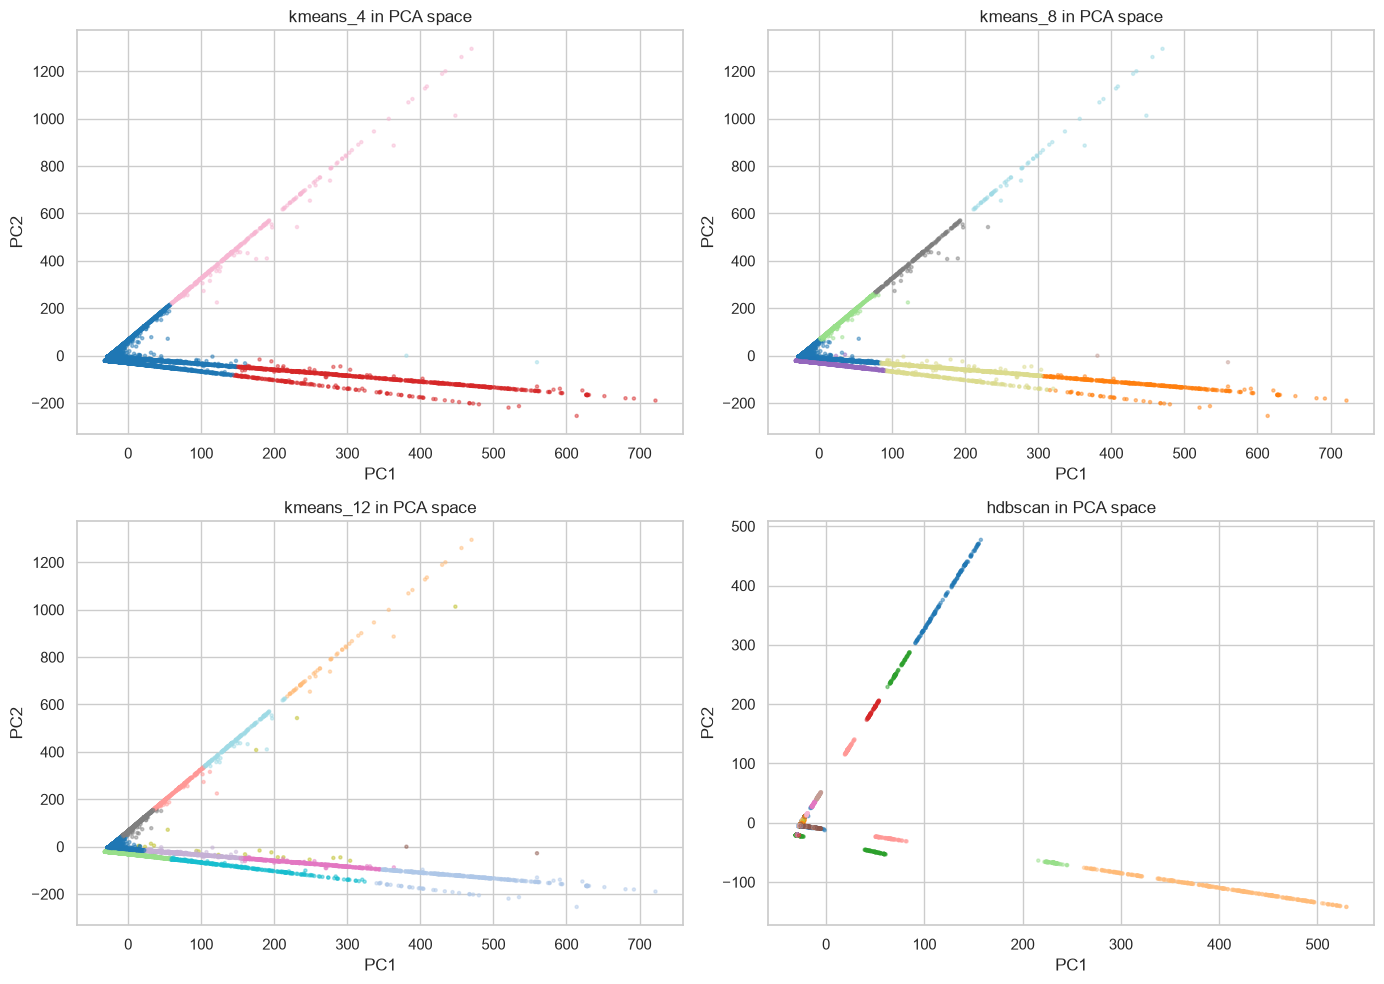

In [3]:
sample['pc1'] = matrix[:, 0]
sample['pc2'] = matrix[:, 1]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, column in zip(axes.flat, ['kmeans_4', 'kmeans_8', 'kmeans_12', 'hdbscan']):
    plot = sample[sample[column] >= 0]
    ax.scatter(plot['pc1'], plot['pc2'], c=plot[column], s=5, alpha=0.45, cmap='tab20')
    ax.set_title(f'{column} in PCA space')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
fig.tight_layout()
fig.savefig(FIGURES / 'model_cluster_pca_grid.png', dpi=180, bbox_inches='tight')
plt.show()

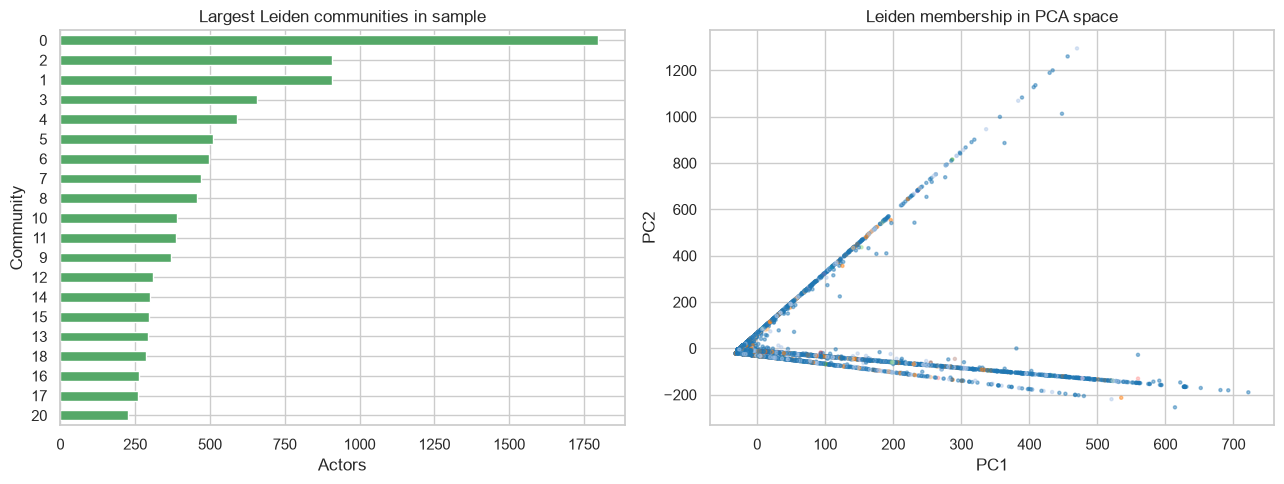

reload check: kmeans_8 8


In [4]:
leiden = pd.read_csv(RESULTS / 'leiden_memberships.csv', index_col='address')['community']
leiden.index = leiden.index.astype(str)
sample['leiden'] = leiden.reindex(sample.index.astype(str)).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sizes = sample['leiden'].value_counts().head(20)
sizes.sort_values().plot.barh(ax=axes[0], color='#55a868')
axes[0].set_title('Largest Leiden communities in sample')
axes[0].set_xlabel('Actors')
axes[0].set_ylabel('Community')
axes[1].scatter(sample['pc1'], sample['pc2'], c=sample['leiden'], s=5, alpha=0.45, cmap='tab20')
axes[1].set_title('Leiden membership in PCA space')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
fig.tight_layout()
fig.savefig(FIGURES / 'leiden_cluster_visualization.png', dpi=180, bbox_inches='tight')
plt.show()
loaded = load_artifact(MODEL_DIR / 'kmeans_8.joblib')
print('reload check:', loaded['method'], loaded['model'].n_clusters)